In [1]:
import numpy as np
import pandas as pd
from PIL import Image

df = pd.read_csv("../data/inventory_final.csv")

for path in df["image_path"].sample(5, random_state=1):
    img = Image.open(path)
    arr = np.array(img)
    print(path.split("/")[-1], "| mode:", img.mode, "| shape:", arr.shape,
          "| dtype:", arr.dtype, "| min/max:", arr.min(), arr.max())

print("\nimage modes in the dataset:")
print(df["image_path"].apply(lambda p: Image.open(p).mode).value_counts())

Tr-me_0463.jpg | mode: RGB | shape: (512, 512, 3) | dtype: uint8 | min/max: 0 255
gg (222).jpg | mode: RGB | shape: (512, 512, 3) | dtype: uint8 | min/max: 0 255
gg (297).jpg | mode: RGB | shape: (512, 512, 3) | dtype: uint8 | min/max: 0 253
Tr-no_0712.jpg | mode: RGB | shape: (417, 428, 3) | dtype: uint8 | min/max: 0 255
Tr-gl_0587.jpg | mode: L | shape: (512, 512) | dtype: uint8 | min/max: 0 255

image modes in the dataset:
image_path
RGB     2899
L        997
RGBA       3
P          1
Name: count, dtype: int64


In [2]:
import numpy as np
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224

def load_image(path):
    img = Image.open(path).convert("RGB")         # always 3 channels
    img = img.resize((IMG_SIZE, IMG_SIZE))        # always 224x224
    arr = np.array(img, dtype=np.float32)         # uint8 -> float32
    return preprocess_input(arr)                  # 0..255 -> -1..1

I0000 00:00:1792959895.990746   52088 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792959895.993159   52088 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792959896.227814   52088 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792959897.395938   52088 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [3]:
import pandas as pd

df = pd.read_csv("../data/inventory_final.csv")

tests = {}
for mode in ["L", "RGB", "RGBA", "P"]:
    for p in df["image_path"]:
        if Image.open(p).mode == mode:
            tests[mode] = p
            break

for mode, p in tests.items():
    x = load_image(p)
    print(mode, "->", x.shape, x.dtype, "| min/max:", x.min(), x.max())

L -> (224, 224, 3) float32 | min/max: -1.0 0.88235295
RGB -> (224, 224, 3) float32 | min/max: -1.0 0.92941177
RGBA -> (224, 224, 3) float32 | min/max: -1.0 1.0
P -> (224, 224, 3) float32 | min/max: -1.0 1.0


In [4]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 32
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
class_to_id = {c: i for i, c in enumerate(CLASSES)}

df = pd.read_csv("../data/inventory_final.csv")

def parse(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = preprocess_input(img)
    return img, label

def make_dataset(split, shuffle=False):
    d = df[df["split"] == split]
    paths = d["image_path"].values
    labels = d["folder_class"].map(class_to_id).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(d), seed=42)
    ds = ds.map(parse, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset("train", shuffle=True)
val_ds = make_dataset("val")
test_ds = make_dataset("test")

# check one batch
images, labels = next(iter(train_ds))
print("batch images:", images.shape, images.dtype)
print("batch labels:", labels.shape, labels.numpy()[:10])
print("min/max:", images.numpy().min(), images.numpy().max())
print("batches -> train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

batch images: (32, 224, 224, 3) <dtype: 'float32'>
batch labels: (32,) [3 1 1 0 3 2 1 0 0 1]
min/max: -1.0 1.0
batches -> train: 91 | val: 16 | test: 16


E0000 00:00:1792960196.684341   52088 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [8]:
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(10 / 360, fill_mode="constant", fill_value=-1.0),
    layers.RandomTranslation(0.1, 0.1, fill_mode="constant", fill_value=-1.0),
    layers.RandomZoom(0.1, fill_mode="constant", fill_value=-1.0),
    layers.RandomContrast(0.1, value_range=(-1, 1)),
], name="data_augmentation")

# apply to the Train dataset only
train_ds_aug = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE,
).prefetch(tf.data.AUTOTUNE)

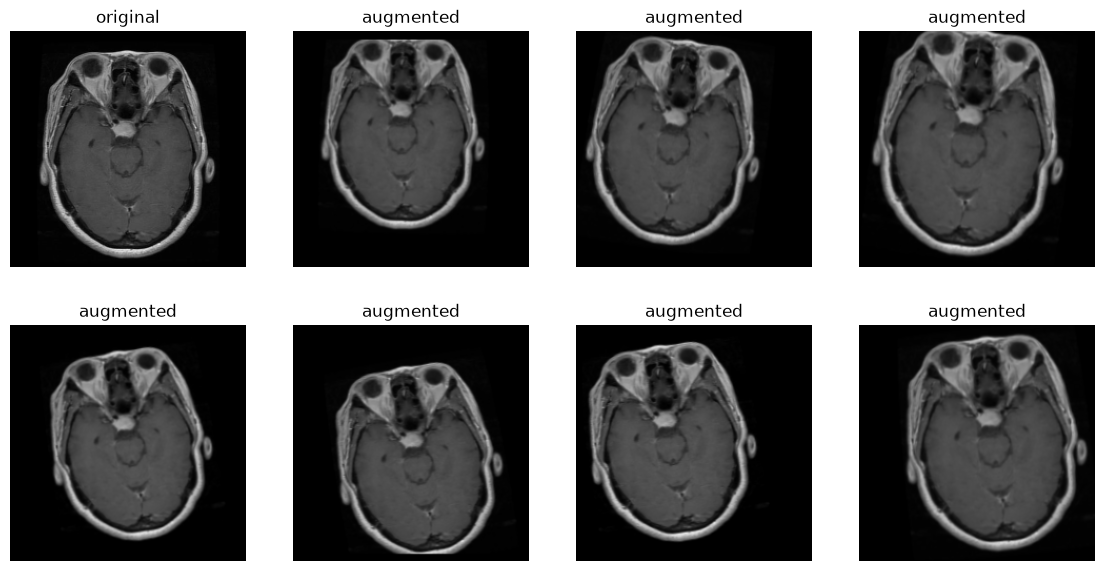

In [10]:
images, labels = next(iter(train_ds))
img = images[0:1]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow((img[0] + 1) / 2)
axes[0, 0].set_title("original")

for ax in axes.flat[1:]:
    aug = data_augmentation(img, training=True)
    ax.imshow(np.clip((aug[0].numpy() + 1) / 2, 0, 1))
    ax.set_title("augmented")

for ax in axes.flat:
    ax.axis("off")
plt.show()